# MADT 7202 Mid-Term · Bangkok district procurement: which supplier group should Internal Audit sample first?

**Source:** Bangkok Metropolitan Administration (BMA) Open Contract, OCDS publication via the Open Contracting Partnership Data Registry
(https://data.open-contracting.org/en/publication/158), file `2026.csv.tar.gz`, downloaded 13 Oct 2026 (records compiled 5 Aug 2026). Licence **CC BY 4.0**. No scraping.

**PDPA:** a sole trader's 13-digit tax ID is their national ID number. Immediately after loading, individuals' IDs are replaced by a salted SHA-256 hash and their names are dropped, so no personal identifier appears in any output below. Juristic persons (companies, partnerships) keep their public tax ID.

In [1]:
import pandas as pd, numpy as np, itertools, networkx as nx, matplotlib.pyplot as plt, hashlib, os, random
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
D = '2026/'   # folder extracted from 2026.csv.tar.gz, next to this notebook
m  = pd.read_csv(D+'main.csv', dtype=str)
aw = pd.read_csv(D+'awards.csv', dtype=str)
sp = pd.read_csv(D+'awards_suppliers.csv', dtype=str)
print('contracting processes', m.ocid.nunique(), '| awards', len(aw), '| award-supplier rows', len(sp))

contracting processes 187996 | awards 4951 | award-supplier rows 3175


## 1. Build the award table (one row = one award to one supplier)

In [2]:
s = sp.merge(m[['ocid','buyer_name','tender_procurementMethodDetails']], left_on='main_ocid', right_on='ocid')
s = s.merge(aw[['main_ocid','id','value_amount']].rename(columns={'id':'awards_id'}), on=['main_ocid','awards_id'], how='left')
s['value'] = pd.to_numeric(s.value_amount)
s['sid'] = s.id.str.zfill(13)                 # 13-digit tax ID
s['fy'] = 'FY25' + s.main_ocid.str[12:14]      # Thai fiscal year (B.E.) from the OCID
s['individual'] = ~s.sid.str.startswith('0')  # juristic IDs start with 0; others = natural persons
# PDPA: pseudonymise natural persons before anything is printed (salt is kept outside the notebook)
SALT = os.environ.get('PDPA_SALT', 'replace-with-private-salt')
pseudo = lambda x: 'P-' + hashlib.sha256((SALT + x).encode()).hexdigest()[:10]
s.loc[s.individual, 'sid'] = s.loc[s.individual, 'sid'].map(pseudo)
s.loc[s.individual, 'name'] = '(individual)'
s = s.drop(columns=['id'])
print('awards with a supplier:', len(s), '| duplicated award rows:', s.duplicated(['main_ocid','awards_id','sid']).sum())
print(s.fy.value_counts().to_dict())
print(s.tender_procurementMethodDetails.value_counts().to_dict())

awards with a supplier: 3175 | duplicated award rows: 0
{'FY2568': 2360, 'FY2569': 814, 'FY2567': 1}
{'วิธีเฉพาะเจาะจง': 3044, 'วิธีประกาศเชิญชวนทั่วไป': 126, 'วิธีคัดเลือก': 5}


## 2. Scope: the 50 district offices only
Central departments (e.g. Health Dept.) buy on behalf of the whole city, so a supplier of a central department would look 'connected' to everything — the same artifact as a seed term. District offices are peers with the same mandate, so they are comparable.

In [3]:
s = s[s.buyer_name.str.startswith('สำนักงานเขต')].copy()
print('district awards', len(s), '| districts', s.buyer_name.nunique(), '| suppliers', s.sid.nunique(), '| THB m', round(s.value.sum()/1e6,1))
print('share individuals', round(s.individual.mean(),3))
print('awards per district:'); print(s.groupby('buyer_name').size().describe().round(1))

district awards 1948 | districts 48 | suppliers 626 | THB m 469.8
share individuals 0.361
awards per district:
count     48.0
mean      40.6
std       49.9
min        1.0
25%        9.8
50%       21.5
75%       49.2
max      204.0
dtype: float64


## 3. Exclude generic nodes: state bodies
The Metropolitan Electricity Authority wins in 15 districts and the War Veterans Organization in 14 — they are public bodies every district must buy from. They play the role of 'price' in the sample report: connected to everything, meaning nothing.

In [4]:
STATE = ['ทหารผ่านศึก','การไฟฟ้า','กรมราชทัณฑ์','สถาบันวิจัย','ทรัพย์สินพระมหากษัตริย์','การท่าเรือ']
s['state'] = s.name.str.contains('|'.join(STATE))
reach_all = s.groupby('sid').agg(name=('name','first'), districts=('buyer_name','nunique')).sort_values('districts', ascending=False)
print(reach_all.head(4))
p = s[~s.state].copy()
print('after exclusion: awards', len(p), '| suppliers', p.sid.nunique())

                                                        name  districts
sid                                                                    
0994000165200                                การไฟฟ้านครหลวง         15
0994000164882                    องค์การสงเคราะห์ทหารผ่านศึก         14
0103531028005  ห้างหุ้นส่วนจำกัด กิตติคุณอิมปอร์ตเอ็กซ์ปอร์ต         10
0105562199547          บริษัท เวิร์ค เวิลด์ คอนเนคชั่น จำกัด         10
after exclusion: awards 1848 | suppliers 620


## 4. The spreadsheet answer (what a non-network audit plan would pick)
Rank suppliers by total value, by number of awards, and by number of districts.

In [5]:
g = p.groupby('sid').agg(name=('name','first'), awards=('main_ocid','size'), value=('value','sum'), districts=('buyer_name','nunique'), individual=('individual','first'))
for col in ['value','awards','districts']:
    g['rank_'+col] = g[col].rank(ascending=False, method='min').astype(int)
print('suppliers winning in only one district:', (g.districts==1).sum(), 'of', len(g))
g.sort_values('value', ascending=False).head(10)[['awards','value','districts']]

suppliers winning in only one district: 487 of 620


,awards,value,districts
sid,,,
0105560041628,50,14211210.00,2
0105541057093,2,12057227.00,2
0105552096761,1,11766383.88,1
0105554130533,1,10999800.00,1
0105524004548,1,9459330.00,1
0125558008082,2,9350000.00,2
0105549062550,1,7865000.00,1
0105535100608,2,7577136.00,2
0105550098104,1,7390000.00,1


## 5. Graph construction
* **Bipartite layer:** district ↔ supplier; an edge asserts *the supplier won at least one award from that district* in FY2568–69.
* **Projection (the graph we analyse):** supplier ↔ supplier; an edge asserts *the two suppliers both won awards in the same district(s)*.
* **Weight:** we compare two choices — raw count of shared districts vs **Jaccard** (shared districts ÷ union of districts).
* Only suppliers active in ≥2 districts can have a projected edge.

In [6]:
ds = p.groupby(['buyer_name','sid']).agg(n=('main_ocid','size'), val=('value','sum')).reset_index()
def project(ds):
    sup = ds.groupby('sid').buyer_name.apply(set)
    sup = sup[sup.apply(len) >= 2]
    rows = []
    for a, b in itertools.combinations(sup.index, 2):
        sh = len(sup[a] & sup[b])
        if sh: rows.append((a, b, sh, sh/len(sup[a] | sup[b])))
    return sup, pd.DataFrame(rows, columns=['a','b','shared','jaccard'])
sup, E = project(ds)
print('multi-district suppliers', len(sup), '| candidate edges', len(E))
def graph(E, min_shared, min_jac):
    e = E[(E.shared >= min_shared) & (E.jaccard >= min_jac)]
    G = nx.Graph(); G.add_weighted_edges_from(e[['a','b','jaccard']].values); return G

multi-district suppliers 133 | candidate edges 2338


### 5a. Construction choice: raw shared-district count vs Jaccard
Raw count favours suppliers that sell everywhere (office equipment); they link to everyone and the graph becomes one blob. Jaccard asks whether two suppliers turn up in the **same** districts relative to how widely each sells.

In [7]:
def summary(G):
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    return dict(nodes=G.number_of_nodes(), edges=G.number_of_edges(), components=len(comps), largest=len(comps[0]) if comps else 0)
G_raw = graph(E, 3, 0.0)
G_jac = graph(E, 3, 0.5)
print('RAW  shared>=3            ', summary(G_raw))
print('JAC  shared>=3, Jaccard>=.5', summary(G_jac))
for c in sorted(nx.connected_components(G_jac), key=len, reverse=True):
    print(len(c), [('IND' if g.loc[x,'individual'] else 'CO') for x in c])

RAW  shared>=3             {'nodes': 34, 'edges': 51, 'components': 2, 'largest': 32}
JAC  shared>=3, Jaccard>=.5 {'nodes': 17, 'edges': 16, 'components': 5, 'largest': 6}
6 ['IND', 'IND', 'IND', 'IND', 'IND', 'IND']
4 ['CO', 'CO', 'CO', 'IND']
3 ['CO', 'CO', 'CO']
2 ['CO', 'CO']
2 ['CO', 'CO']


## 6. The tight group (largest Jaccard component)

In [8]:
pack = max(nx.connected_components(G_jac), key=len)
pk = p[p.sid.isin(pack)]
H = G_jac.subgraph(pack)
print('members', len(pack), '| all individuals:', g.loc[list(pack),'individual'].all())
print('internal edges', H.number_of_edges(), 'of', len(pack)*(len(pack)-1)//2, '| density', round(nx.density(H),2))
print('mean Jaccard on edges', round(np.mean([d['weight'] for *_, d in H.edges(data=True)]),2))
print('awards', pk.main_ocid.nunique(), '| THB', pk.value.sum(), '| methods', pk.tender_procurementMethodDetails.value_counts().to_dict())
print('districts', pk.groupby('buyer_name').sid.nunique().sort_values(ascending=False).to_dict())
g.loc[list(pack), ['awards','value','districts','rank_value','rank_awards','rank_districts']]

members 6 | all individuals: True
internal edges 9 of 15 | density 0.6
mean Jaccard on edges 0.63
awards 40 | THB 3595718.0 | methods {'วิธีเฉพาะเจาะจง': 40}
districts {'สำนักงานเขตหนองจอก': 6, 'สำนักงานเขตตลิ่งชัน': 5, 'สำนักงานเขตทวีวัฒนา': 4, 'สำนักงานเขตคลองสามวา': 4, 'สำนักงานเขตบึงกุ่ม': 2, 'สำนักงานเขตคันนายาว': 1, 'สำนักงานเขตดินแดง': 1, 'สำนักงานเขตลาดพร้าว': 1}


,awards,value,districts,rank_value,rank_awards,rank_districts
sid,,,,,,
P-dc80fbfe01,4,376980.0,4,198,100,16
P-ecfd31ea54,5,480800.0,4,145,78,16
P-cf2147b039,9,1339598.0,3,49,34,32
P-1a4b08fe81,9,534150.0,4,122,34,16
P-a4046a43f4,7,343730.0,4,216,54,16
P-865447ef91,6,520460.0,5,128,65,9


In [9]:
top_val = set(g.sort_values('value', ascending=False).head(20).index)
top_reach = set(g.sort_values(['districts','value'], ascending=False).head(20).index)
print('pack members in top-20 by value:', len(pack & top_val), '| in top-20 by district reach:', len(pack & top_reach))
print('best value rank of any member:', g.loc[list(pack),'rank_value'].min(), 'of', len(g))

pack members in top-20 by value: 0 | in top-20 by district reach: 2
best value rank of any member: 49 of 620


### 6b. What the group buys in Nong Chok (sample of awards)
The annual stationery + computer-supplies order in Nong Chok went to a different group member each time.

In [10]:
ai = pd.read_csv(D+'awards_items.csv', dtype=str)
x = pk[pk.buyer_name.str.contains('หนองจอก')].merge(ai[['main_ocid','description']], on='main_ocid', how='left')
order = g.loc[list(pack)].sort_values(['districts','value'], ascending=False).index   # salt-independent order
code_of = {sid: f'T{i+1}' for i, sid in enumerate(order)}
x['member'] = x.sid.map(code_of)
x[['member','fy','value','description']].drop_duplicates(['member','value']).sort_values('fy')

,member,fy,value,description
0,T5,FY2568,101330.0,วัสดุสำหรับจัดกิจกรรมประเพณีแห่เทียนพรรษา ประจำปี พ.ศ. 2...
1,T1,FY2568,80000.0,จัดซื้อวัสดุปรับปรุงศูนย์ฯ และวัสดุเกษตร จำนวน 36 รายการ...
4,T2,FY2568,17850.0,วัสดุสำนักงาน จำนวน 1 รายการ โดยวิธีเฉพาะเจาะจง
5,T5,FY2568,15700.0,วัสดุสำหรับจัดกิจกรรมเนื่องในโอกาสวันเฉลิมพระชนมพรรษา พร...
7,T2,FY2568,150000.0,วัสดุสำนักงานประเภทเครื่องเขียน แบบพิมพ์ 21รายการ และวัส...
8,T3,FY2568,155500.0,วัสดุสำนักงานประเภทเครื่องเขียน แบบพิมพ์ จำนวน ๒๐ รายการ...
9,T2,FY2568,42500.0,วัสดุสำหรับ บ้านหนังสือ จำนวน 27 รายการ โดยวิธีเฉพาะเจาะจง
13,T5,FY2568,9000.0,วัสดุในการจัดกิจกรรมพิเศษของสภาเด็กและเยาวชนกรุงเทพมหาคร...
14,T4,FY2568,106250.0,วัสดุสำหรับจัดกิจกรรมครอบครัวรักการอ่าน จำนวน 29 รายการ ...
2,T6,FY2569,201300.0,วัสดุสำนักงานประเภทเครื่องเขียน แบบพิมพ์ ๒๙ รายการ และวั...


## 7. Robustness
Sweep the two cutoffs and re-run on FY2568 alone. Question: do the same members stay together in one component?

In [11]:
rows = []
for ms in [2, 3, 4]:
    for jt in [0.0, 0.4, 0.5, 0.6]:
        G = graph(E, ms, jt); comps = list(nx.connected_components(G))
        best = max(comps, key=lambda c: len(c & pack)) if comps else set()
        rows.append(dict(min_shared=ms, min_jaccard=jt, **summary(G), members_together=len(best & pack), their_component=len(best)))
R = pd.DataFrame(rows); print(R.to_string(index=False))
_, E68 = project(p[p.fy=='FY2568'].groupby(['buyer_name','sid']).size().reset_index(name='n'))
G68 = graph(E68, 2, 0.5); best = max(nx.connected_components(G68), key=lambda c: len(c & pack))
print('FY2568 only (shared>=2, J>=0.5): members together', len(best & pack), 'in component of', len(best))
Gs, _ = None, None
_, Es = project(s.groupby(['buyer_name','sid']).size().reset_index(name='n'))
Gs = graph(Es, 3, 0.5); best = max(nx.connected_components(Gs), key=lambda c: len(c & pack))
print('state bodies kept (3, 0.5): members together', len(best & pack), 'in component of', len(best))

 min_shared  min_jaccard  nodes  edges  components  largest  members_together  their_component
          2          0.0    111    379           2      109                 6              109
          2          0.4     88    170          11       42                 6               19
          2          0.5     78    113          15       18                 6               14
          2          0.6     55     77          14       11                 6                7
          3          0.0     34     51           2       32                 6               32
          3          0.4     19     20           4        8                 6                7
          3          0.5     17     16           5        6                 6                6
          3          0.6     12     10           4        6                 6                6
          4          0.0      9      7           2        7                 2                2
          4          0.4      6      3           3

state bodies kept (3, 0.5): members together 6 in component of 6


## 7b. Null model: could a group like this arise by chance?
Projection turns every district into a clique of its suppliers, so busy districts create links automatically. Test: **degree-preserving rewiring** of the district ↔ supplier graph (each district keeps its number of suppliers, each supplier its number of districts), 300 randomised graphs, same cutoffs (≥ 3 shared districts, Jaccard ≥ 0.5).

In [12]:
BE = list(p[['buyer_name','sid']].drop_duplicates().itertuples(index=False, name=None))
def stat(edges):
    sup = {}
    for d, x in edges: sup.setdefault(x, set()).add(d)
    sup = {k: v for k, v in sup.items() if len(v) >= 2}
    G = nx.Graph()
    for a, b in itertools.combinations(sup, 2):
        sh = len(sup[a] & sup[b])
        if sh >= 3 and sh/len(sup[a] | sup[b]) >= 0.5: G.add_edge(a, b)
    return G.number_of_edges(), max([len(c) for c in nx.connected_components(G)] or [0])
def rewire(edges, n):
    e = list(edges); S = set(e)
    for _ in range(n):
        i, j = random.sample(range(len(e)), 2); (d1, s1), (d2, s2) = e[i], e[j]
        if d1 == d2 or s1 == s2 or (d1, s2) in S or (d2, s1) in S: continue
        S -= {e[i], e[j]}; e[i], e[j] = (d1, s2), (d2, s1); S |= {e[i], e[j]}
    return e
obs = stat(BE); random.seed(1); cur = BE; null = []
for _ in range(300):
    cur = rewire(cur, 3000); null.append(stat(cur))
null = np.array(null)
print('observed: edges', obs[0], '| largest group', obs[1])
print('null:     edges mean %.1f (max %d) | largest group mean %.1f (max %d)' % (null[:,0].mean(), null[:,0].max(), null[:,1].mean(), null[:,1].max()))
print('p(edges >= observed) = %.3f | p(largest group >= observed) = %.3f' % ((null[:,0] >= obs[0]).mean(), (null[:,1] >= obs[1]).mean()))

observed: edges 16 | largest group 6
null:     edges mean 3.4 (max 11) | largest group mean 2.6 (max 8)
p(edges >= observed) = 0.000 | p(largest group >= observed) = 0.027


## 8. Figure

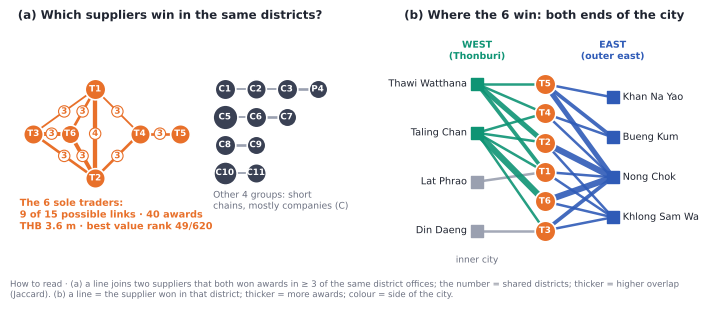

line crossings in (b): 12


In [13]:
EN = {'คลองสามวา':'Khlong Sam Wa','หนองจอก':'Nong Chok','คันนายาว':'Khan Na Yao','บึงกุ่ม':'Bueng Kum','ตลิ่งชัน':'Taling Chan',
      'ทวีวัฒนา':'Thawi Watthana','ดินแดง':'Din Daeng','ลาดพร้าว':'Lat Phrao'}
SIDE = {'Khlong Sam Wa':'east','Nong Chok':'east','Khan Na Yao':'east','Bueng Kum':'east',
        'Taling Chan':'west','Thawi Watthana':'west','Din Daeng':'inner','Lat Phrao':'inner'}
ORANGE, EAST, WEST, INNER, INK, MUTED, DARK = '#E8702A', '#2F5BB7', '#0E9474', '#9AA0B0', '#1F2430', '#6B7080', '#3A4154'
REGION = {'east': EAST, 'west': WEST, 'inner': INNER}
plt.rcParams.update({'font.family': 'DejaVu Sans'})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.7), gridspec_kw={'width_ratios': [1.1, 1]})

# ---------- (a) supplier <-> supplier projection ----------
G = G_jac
shared = {frozenset((r.a, r.b)): r.shared for r in E.itertuples()}
inv = {v: k for k, v in code_of.items()}
# planar hand layout: T1,T2,T3,T6 are fully linked (drawn as a triangle with T6 inside); T4-T5 hang off T1/T2
pos = {inv['T1']: (0, 1.15), inv['T2']: (0, -1.15), inv['T3']: (-1.6, 0), inv['T6']: (-0.65, 0),
       inv['T4']: (1.15, 0), inv['T5']: (2.2, 0)}
others = sorted([c for c in nx.connected_components(G) if c != pack], key=len, reverse=True)
lab, k = {}, 0
for row, comp in enumerate(others):
    sub = G.subgraph(comp)
    chain = list(nx.dfs_preorder_nodes(sub, min(sub.nodes, key=sub.degree)))
    for j, n in enumerate(chain):
        pos[n] = (3.35 + 0.8*j, 1.15 - 0.72*row)
        k += 1; lab[n] = ('P' if g.loc[n, 'individual'] else 'C') + str(k)
lab.update({n: code_of[n] for n in pack})
for u, v, d in G.edges(data=True):
    inside = u in pack and v in pack
    (x1, y1), (x2, y2) = pos[u], pos[v]
    ax1.plot([x1, x2], [y1, y2], color=ORANGE if inside else INNER, lw=1.0 + 6*(d['weight'] - 0.45),
             solid_capstyle='round', zorder=1)
    if inside:
        ax1.text((x1 + x2)/2, (y1 + y2)/2, str(shared[frozenset((u, v))]), ha='center', va='center', fontsize=6.3,
                 color=ORANGE, fontweight='bold', zorder=3,
                 bbox=dict(boxstyle='circle,pad=0.15', fc='white', ec=ORANGE, lw=0.8))
for n in G.nodes:
    x, y = pos[n]
    ax1.scatter(x, y, s=120 + 20*g.loc[n, 'districts'], color=ORANGE if n in pack else DARK,
                edgecolor='white', linewidth=1.2, zorder=4)
    ax1.text(x, y, lab[n], ha='center', va='center', fontsize=6.3, color='white', fontweight='bold', zorder=5)
ax1.text(-1.95, -1.65, 'The 6 sole traders:\n9 of 15 possible links · 40 awards\nTHB 3.6 m · best value rank 49/620',
         fontsize=7, color=ORANGE, fontweight='bold', va='top')
ax1.text(3.05, -1.45, 'Other 4 groups: short\nchains, mostly companies (C)', fontsize=6.6, color=MUTED, va='top')
ax1.set_xlim(-2.0, 6.0); ax1.set_ylim(-2.55, 1.5); ax1.set_aspect('equal'); ax1.axis('off')

# ---------- (b) west districts <- the 6 -> east districts, orders chosen to minimise crossings ----------
cnt = pk.groupby(['sid', 'buyer_name']).size()
links = [(code_of[sid], EN[b.replace('สำนักงานเขต', '')], n) for (sid, b), n in cnt.items()]
mem0 = sorted({a for a, _, _ in links})
right = sorted({b for _, b, _ in links if SIDE[b] == 'east'})
left = sorted({b for _, b, _ in links if SIDE[b] != 'east'})
def order_side(side, pm):   # barycenter, inner-city districts kept below the west side
    return sorted(side, key=lambda d: (SIDE[d] == 'inner', np.mean([pm[a] for a, b, _ in links if b == d])))
def crossings(pm, pd_):
    L = [(pm[a], pd_[b]) for a, b, _ in links if b in pd_]
    return sum(1 for (a1, b1), (a2, b2) in itertools.combinations(L, 2) if (a1 - a2)*(b1 - b2) < 0)
best = None
for mo in itertools.permutations(mem0):
    pm = {m: i for i, m in enumerate(mo)}
    lo, ro = order_side(left, pm), order_side(right, pm)
    c = crossings(pm, {d: i for i, d in enumerate(lo)}) + crossings(pm, {d: i for i, d in enumerate(ro)})
    if best is None or c < best[0]: best = (c, mo, lo, ro)
_, mo, lo, ro = best
span = 4.4
ym = {m: -i*span/(len(mo) - 1) for i, m in enumerate(mo)}
yl = {d: -i*span/(len(lo) - 1) for i, d in enumerate(lo)}
yr = {d: -0.4 - i*(span - 0.8)/(len(ro) - 1) for i, d in enumerate(ro)}
XL, XM, XR = 0, 1.35, 2.7
for a, b, n in sorted(links, key=lambda t: t[2]):
    x, y = (XR, yr[b]) if b in yr else (XL, yl[b])
    ax2.plot([XM, x], [ym[a], y], color=REGION[SIDE[b]], lw=0.9 + 0.9*n, alpha=0.9, solid_capstyle='round', zorder=1)
for m in mo:
    ax2.scatter(XM, ym[m], s=220, color=ORANGE, edgecolor='white', linewidth=1.2, zorder=3)
    ax2.text(XM, ym[m], m, ha='center', va='center', fontsize=6.3, color='white', fontweight='bold', zorder=4)
for d in lo:
    ax2.scatter(XL, yl[d], s=85, marker='s', color=REGION[SIDE[d]], zorder=3)
    ax2.text(XL - 0.2, yl[d], d, va='center', ha='right', fontsize=7, color=INK)
for d in ro:
    ax2.scatter(XR, yr[d], s=85, marker='s', color=EAST, zorder=3)
    ax2.text(XR + 0.2, yr[d], d, va='center', fontsize=7, color=INK)
ax2.text(XL, 0.75, 'WEST\n(Thonburi)', ha='center', fontsize=6.8, color=WEST, fontweight='bold')
ax2.text(XL, -span - 0.75, 'inner city', ha='center', fontsize=6.5, color=MUTED, va='top')
ax2.text(XR, 0.75, 'EAST\n(outer east)', ha='center', fontsize=6.8, color=EAST, fontweight='bold')
ax2.set_xlim(-1.45, 4.15); ax2.set_ylim(-span - 1.3, 1.5); ax2.axis('off')
fig.text(0.01, -0.03, 'How to read · (a) a line joins two suppliers that both won awards in ≥ 3 of the same district offices; '
         'the number = shared districts; thicker = higher overlap (Jaccard). (b) a line = the supplier won in that district; '
         'thicker = more awards; colour = side of the city.', fontsize=6.2, color=MUTED, wrap=True)
plt.tight_layout()
for ax, ttl in [(ax1, '(a) Which suppliers win in the same districts?'), (ax2, '(b) Where the 6 win: both ends of the city')]:
    fig.text(ax.get_position().x0, 0.99, ttl, fontsize=8.5, fontweight='bold', color=INK, va='bottom')
plt.savefig('figure.png', dpi=300, bbox_inches='tight'); plt.show()
print('line crossings in (b):', best[0])

## 9. Export the analysis dataset (pseudonymised, safe to share)
District-office awards after scoping, with natural persons already hashed and names dropped (section 1). This is the file published in the repository.

In [14]:
out = s[['main_ocid','fy','buyer_name','sid','name','individual','state','tender_procurementMethodDetails','value']].rename(
    columns={'main_ocid':'ocid','buyer_name':'district_office','sid':'supplier_id','name':'supplier_name',
             'state':'excluded_state_body','tender_procurementMethodDetails':'procurement_method','value':'award_value_thb'})
out.to_csv('district_awards_pseudonymised.csv', index=False, encoding='utf-8-sig')
print(out.shape, '| individuals', out.individual.sum(), '| 13-digit IDs of individuals left:',
      out.loc[out.individual, 'supplier_id'].str.fullmatch(r'\d{13}').sum())

(1948, 9) | individuals 703 | 13-digit IDs of individuals left: 0
